# OrgPilot AI — 분석 노트북

> ⚠ 이 노트북의 모든 데이터는 **합성(synthetic) 데이터**입니다. 가상 기업 *Aster Digital*을 가정해 `src/data_gen.py`로 생성했습니다.

모든 수치는 `src/` 모듈의 함수가 계산하며, 노트북은 호출·시각화만 합니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data_gen import SCHEMA, load
from src import forecast as F, kpi, staffing as S

plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110,
})
IMG = ROOT / "docs" / "images"
IMG.mkdir(parents=True, exist_ok=True)

# 색 역할: 과부하(red) / 적정(gray) / 저활용(blue) — 1.0 기준 양극(diverging) 인코딩, 항상 텍스트 라벨 병기
STATUS_COLOR = {"과부하": "#e34948", "적정": "#a3a29b", "저활용": "#2a78d6"}
INK, MUTED = "#0b0b0b", "#52514e"

tables = {name: load(name) for name in SCHEMA}
{name: len(df) for name, df in tables.items()}

{'departments': 8,
 'employees': 300,
 'workload': 192,
 'skills': 1199,
 'staffing_plan': 192}

## Module A. 조직 생산성 진단

**KPI 정의** (`src/kpi.py`)

| KPI | 정의 |
|---|---|
| 필요 FTE | 업무건수 × 건당 표준시간 / 1인당 월 가용시간(140h) |
| 업무부하율 | 필요시간 / 가용시간 (가용시간 = 현원 × active 비율 × 140h) |
| 1인당 처리량 | 월 업무건수 / 가용인원 *(조직마다 업무 단위가 달라 조직 간 비교 불가, 조직 내 추이용)* |
| 초과근무 추정 | max(0, 필요시간 − 가용시간) / 가용인원 — 부족분을 초과근무로 메운다고 가정한 상한 |
| 상태 | 부하율 > 1.05 과부하, < 0.95 저활용, 그 외 적정 |

스냅샷은 최근 12개월(2025-10 ~ 2026-09)을 집계합니다.

In [2]:
k = kpi.department_kpis(tables).sort_values("load_ratio", ascending=False)
cols = {"name": "조직", "headcount": "현원", "active_headcount": "가용인원", "approved_to": "정원(TO)",
        "required_fte": "필요 FTE", "load_ratio": "부하율", "peak_load_ratio": "최대 월부하율",
        "overtime_per_person": "1인당 월 초과(h)", "overload_months": "과부하 개월수",
        "workload_yoy": "업무량 YoY", "status": "상태"}
(k[list(cols)].rename(columns=cols).style.hide(axis="index")
 .format({"필요 FTE": "{:.1f}", "부하율": "{:.2f}", "최대 월부하율": "{:.2f}",
          "1인당 월 초과(h)": "{:.1f}", "업무량 YoY": "{:+.0%}"}))

조직,현원,가용인원,정원(TO),필요 FTE,부하율,최대 월부하율,1인당 월 초과(h),과부하 개월수,업무량 YoY,상태
AI서비스팀,24,23,26,29.3,1.37,1.53,52.3,12,+26%,과부하
클라우드인프라팀,38,37,38,43.0,1.21,1.29,29.4,12,+17%,과부하
정보보안팀,22,22,23,23.7,1.11,1.22,15.1,11,+7%,과부하
SI사업1팀,55,54,58,56.9,1.05,1.24,9.3,6,+4%,적정
PMO팀,30,30,30,29.8,0.99,1.11,4.3,5,+5%,적정
IT운영팀,50,47,52,46.5,0.97,1.07,1.4,4,-6%,적정
SI사업2팀,48,46,52,43.4,0.93,1.05,0.6,2,-2%,저활용
경영지원팀,33,33,35,28.6,0.85,0.97,0.0,0,-2%,저활용


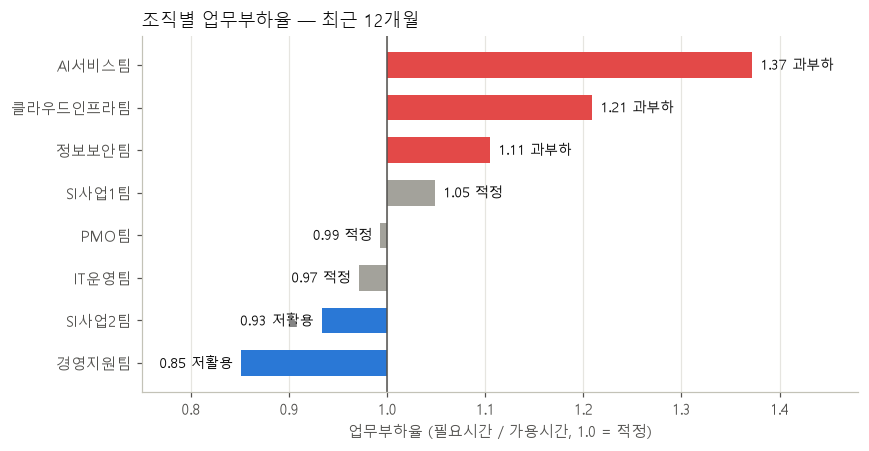

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
kk = k.sort_values("load_ratio")
bars = ax.barh(kk["name"], kk["load_ratio"] - 1, left=1, height=0.6,
               color=kk["status"].map(STATUS_COLOR))
ax.axvline(1, color=MUTED, lw=1)
for y, (v, s) in enumerate(zip(kk["load_ratio"], kk["status"])):
    off = 0.008 if v >= 1 else -0.008
    ax.text(v + off, y, f"{v:.2f} {s}", va="center", ha="left" if v >= 1 else "right", color=INK, fontsize=9)
ax.set_xlim(0.75, 1.48)
ax.set_xlabel("업무부하율 (필요시간 / 가용시간, 1.0 = 적정)")
ax.set_title("조직별 업무부하율 — 최근 12개월", loc="left", color=INK)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(IMG / "a_load_ratio.png", bbox_inches="tight")

### 월별 업무부하율 추이
조직마다 하나의 패널(small multiples), 공통 y축. 점선 = 1.0(적정).

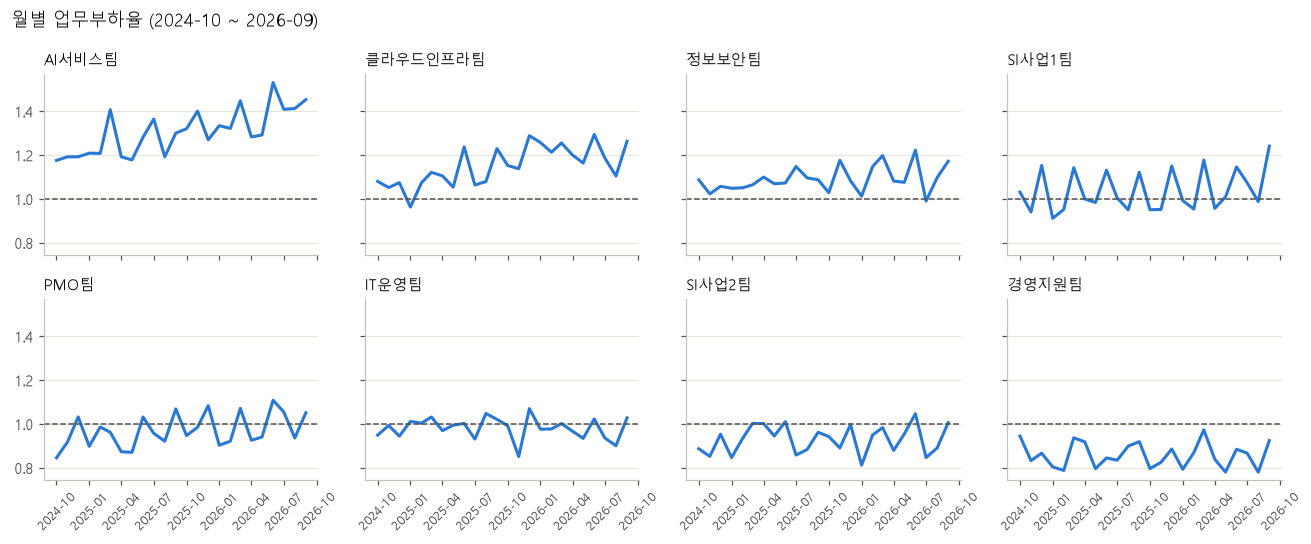

In [4]:
m = kpi.monthly_metrics(tables)
order = k["department_id"].tolist()
names = k.set_index("department_id")["name"]
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True)
for ax, d in zip(axes.flat, order):
    g = m[m["department_id"] == d]
    x = pd.PeriodIndex(g["period"], freq="M").to_timestamp()
    ax.plot(x, g["load_ratio"], color="#2a78d6", lw=2)
    ax.axhline(1, color=MUTED, lw=1, ls="--")
    ax.set_title(names[d], loc="left", fontsize=10, color=INK)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
fig.suptitle("월별 업무부하율 (2024-10 ~ 2026-09)", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(IMG / "a_monthly_load.png", bbox_inches="tight")

### 정원(TO)은 업무량을 반영하고 있는가
현재 정원은 "직전 연말 현원 + 부서 요청분"으로 정해졌습니다. 필요 FTE(최근 12개월 평균)와 나란히 놓으면 차이가 드러납니다.

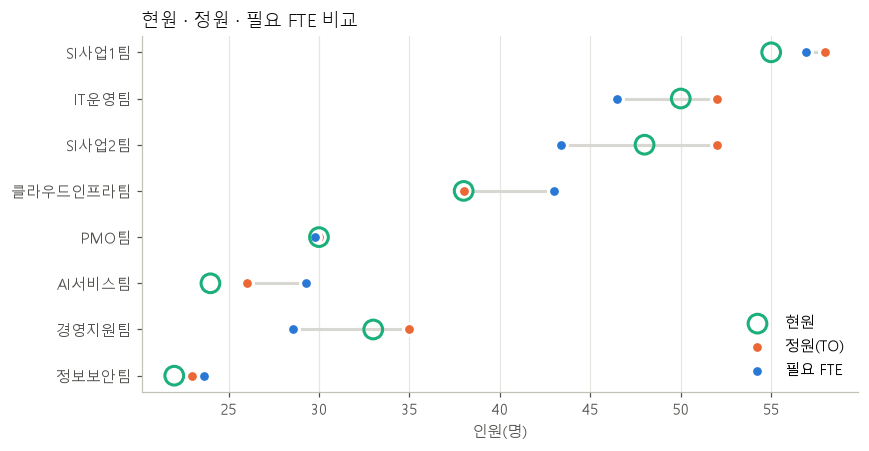

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
kk = k.sort_values("required_fte")
y = range(len(kk))
ax.hlines(y, kk[["approved_to", "required_fte"]].min(axis=1), kk[["approved_to", "required_fte"]].max(axis=1),
          color="#d8d7d1", lw=2)
# 현원은 속이 빈 큰 원: 정원·필요 FTE와 값이 겹쳐도 가려지지 않도록
ax.scatter(kk["headcount"], y, s=150, facecolor="none", edgecolor="#1baf7a", lw=2, label="현원", zorder=5)
ax.scatter(kk["approved_to"], y, s=60, color="#eb6834", label="정원(TO)", zorder=3, edgecolor="white", lw=2)
ax.scatter(kk["required_fte"], y, s=60, color="#2a78d6", label="필요 FTE", zorder=4, edgecolor="white", lw=2)
ax.set_yticks(list(y), kk["name"])
ax.set_xlabel("인원(명)")
ax.set_title("현원 · 정원 · 필요 FTE 비교", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(IMG / "a_to_vs_need.png", bbox_inches="tight")

In [6]:
gap = k.assign(정원_필요차=(k["approved_to"] - k["required_fte"]).round(1))[["name", "approved_to", "required_fte", "정원_필요차", "status"]]
gap.sort_values("정원_필요차").style.hide(axis="index").format({"required_fte": "{:.1f}"})

name,approved_to,required_fte,정원_필요차,status
클라우드인프라팀,38,43.0,-5.000000,과부하
AI서비스팀,26,29.3,-3.300000,과부하
정보보안팀,23,23.7,-0.700000,과부하
PMO팀,30,29.8,0.200000,적정
SI사업1팀,58,56.9,1.100000,적정
IT운영팀,52,46.5,5.500000,적정
경영지원팀,35,28.6,6.400000,저활용
SI사업2팀,52,43.4,8.600000,저활용


**해석 (Module A)**
- 과부하 조직은 업무량이 전년 대비 크게 늘어난 조직과 겹칩니다. 연초 1회 "현원 + 요청분"으로 정해지는 정원은 연중 성장을 따라가지 못합니다.
- 저활용 조직은 업무량이 줄었지만 정원은 과거 현원 기준으로 유지되어, 필요 인원보다 정원이 큽니다.
- 부하율이 연평균으로 적정이어도 분기말 피크에는 1.0을 넘는 조직이 있습니다(최대 월부하율·과부하 개월수 참고). 정원은 평균 기준으로, 피크는 일시 지원·초과근무로 대응할지 판단이 필요합니다.
- 다음 단계(Module B): 과거 평균이 아니라 **향후 업무량 예측**으로 필요 FTE를 산정합니다.

## Module B. 업무량 예측 + 적정 TO 산정

**흐름**: 월 업무건수 예측(`src/forecast.py`) → 필요 FTE 변환 → 권장 정원·인력 격차 → 민감도(`src/staffing.py`)

### B-1. 예측 모델 선택과 Rolling-origin 검증

| 모델 | 설명 | 역할 |
|---|---|---|
| baseline_mean | 최근 12개월 평균 | 현행 관행("작년 수준 유지")의 대리 지표 |
| **seasonal_trend** | 조직별 `log(업무건수) = a + b·t + c·분기말 + d·1월` | **주 모델** — 계수가 곧 월 성장률·분기말 증가폭이라 설명 가능 |
| xgboost | 조직·t·월·분기말 특성 | 비교용 |

검증: 첫 12개월로 학습 → 1~6개월 뒤 예측, 기준점을 한 달씩 옮기며 반복(기준점 12개). 기준점 이후 데이터는 학습에 쓰지 않습니다.

In [7]:
df = F.prepare(tables["workload"])
bt = F.backtest(df)
summary = F.summarize_backtest(bt)
summary.style.format("{:.1%}").set_caption(
    "monthly_wape: 월 단위 오차 / level_wape: 예측 구간 평균 수준 오차(정원 산정에 쓰이는 값) / "
    "level_err_p90: 평균 수준 오차의 90분위 / bias: 과대(+)·과소(−) 예측")

,monthly_wape,level_wape,level_err_p90,bias
seasonal_trend,3.5%,2.4%,4.6%,0.7%
xgboost,4.6%,3.6%,6.1%,0.1%
baseline_mean,6.6%,5.0%,14.0%,-0.4%


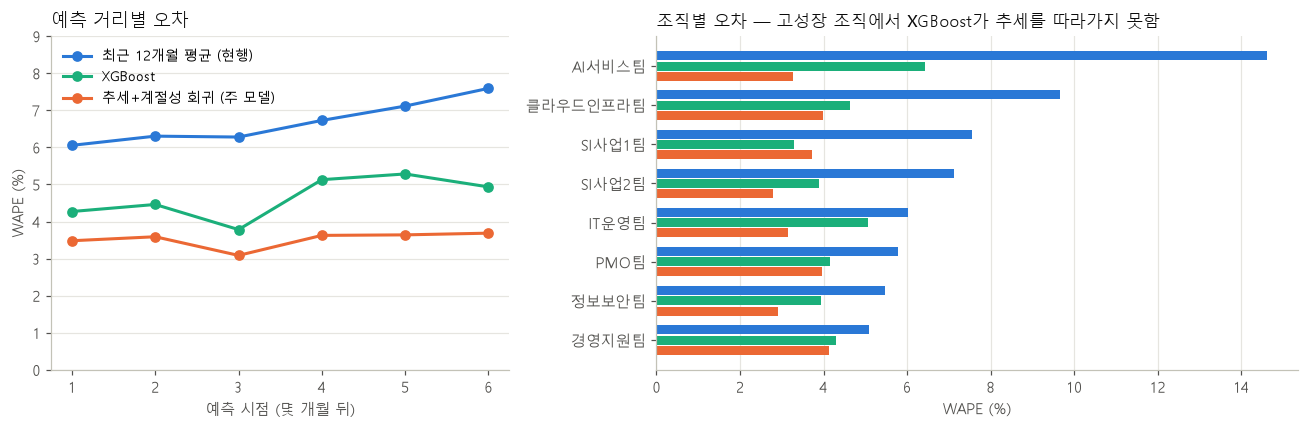

In [8]:
MODEL_COLOR = {"baseline_mean": "#2a78d6", "seasonal_trend": "#eb6834", "xgboost": "#1baf7a"}
MODEL_LABEL = {"baseline_mean": "최근 12개월 평균 (현행)", "seasonal_trend": "추세+계절성 회귀 (주 모델)", "xgboost": "XGBoost"}
by_h = F.wape_by(bt, "h")
by_d = F.wape_by(bt, "department_id").rename(index=names)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
for mname in ["baseline_mean", "xgboost", "seasonal_trend"]:
    a1.plot(by_h.index, by_h[mname] * 100, marker="o", ms=6, lw=2, color=MODEL_COLOR[mname], label=MODEL_LABEL[mname])
a1.set_xlabel("예측 시점 (몇 개월 뒤)"); a1.set_ylabel("WAPE (%)"); a1.set_ylim(0, 9)
a1.set_title("예측 거리별 오차", loc="left", color=INK); a1.legend(frameon=False, fontsize=9)
a1.grid(axis="y", color="#e6e5e0", lw=0.8)

dd = by_d.sort_values("baseline_mean")
yy = np.arange(len(dd)); w = 0.26
for i, mname in enumerate(["baseline_mean", "xgboost", "seasonal_trend"]):
    a2.barh(yy + (1 - i) * w, dd[mname] * 100, height=w - 0.03, color=MODEL_COLOR[mname], label=MODEL_LABEL[mname])
a2.set_yticks(yy, dd.index); a2.set_xlabel("WAPE (%)")
a2.set_title("조직별 오차 — 고성장 조직에서 XGBoost가 추세를 따라가지 못함", loc="left", color=INK, fontsize=11)
a2.grid(axis="x", color="#e6e5e0", lw=0.8); a2.set_axisbelow(True)
fig.tight_layout(); fig.savefig(IMG / "b_backtest.png", bbox_inches="tight")

**해석**
- 주 모델의 월 단위 오차(약 3.5%)는 데이터에 넣은 무작위 변동(월 ±4% 수준)이 만드는 하한에 가깝습니다. 남은 오차는 대부분 예측할 수 없는 변동입니다.
- **XGBoost는 학습 범위 밖의 t에 대해 마지막 값 근처를 반복**(트리 모델은 외삽 불가)하므로, AI서비스팀처럼 계속 성장하는 조직에서 오차가 2배로 커집니다. 데이터가 조직당 24개월뿐인 상황에서는 단순하고 해석 가능한 회귀가 더 적합합니다.
- 현행 관행(12개월 평균)은 성장 조직에서 체계적으로 **과소 예측**합니다 → 성장 조직의 정원 부족이 반복되는 원인.

**추정된 계수** (전체 24개월 학습)

In [9]:
coef = F.fit_seasonal_trend(df)
coef_view = pd.DataFrame({
    "조직": names[coef.index],
    "월 성장률": np.expm1(coef["t"]),
    "연 환산 성장률": np.expm1(coef["t"] * 12),
    "분기말 증가폭": np.expm1(coef["qend"]),
    "1월 증감": np.expm1(coef["jan"]),
})
coef_view.style.hide(axis="index").format({c: "{:+.1%}" for c in coef_view.columns[1:]})

조직,월 성장률,연 환산 성장률,분기말 증가폭,1월 증감
SI사업1팀,+0.3%,+3.8%,+17.0%,-3.9%
SI사업2팀,-0.2%,-2.4%,+11.8%,-7.7%
클라우드인프라팀,+1.3%,+16.6%,+7.8%,+0.1%
AI서비스팀,+2.0%,+26.4%,+4.6%,-3.1%
PMO팀,+0.4%,+4.8%,+12.0%,-2.6%
IT운영팀,-0.5%,-6.1%,+6.4%,+2.1%
정보보안팀,+0.6%,+7.5%,+5.1%,-5.3%
경영지원팀,-0.2%,-2.3%,+7.9%,-2.8%


1월 계수는 학습 기간에 1월이 두 번뿐이라 불확실성이 큽니다. 성장률·분기말 계수가 정원 산정에 주로 영향을 줍니다.

### B-2. 향후 12개월 예측 (2026-10 ~ 2027-09)

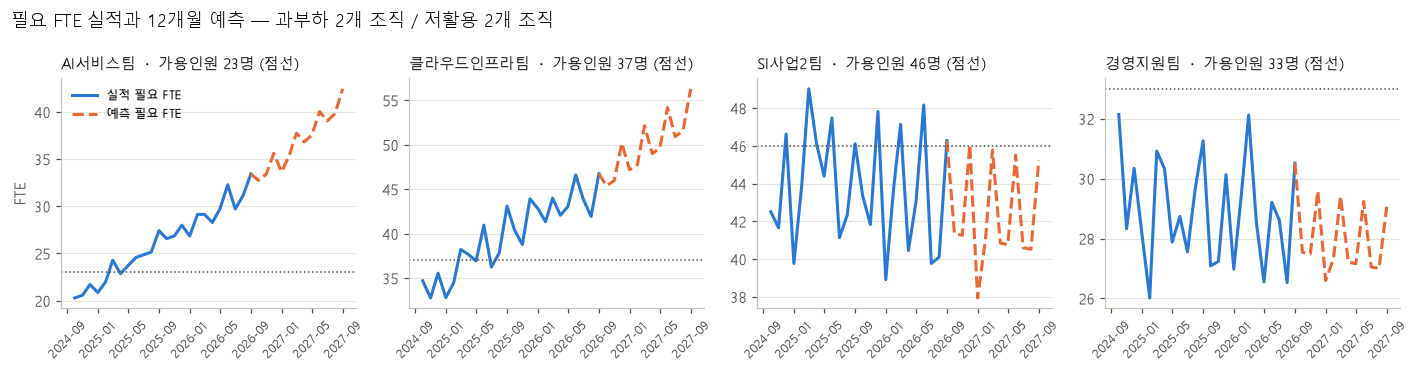

In [10]:
fc, table, sens = S.run(tables)
show = ["D04", "D03", "D02", "D08"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharex=True)
for ax, d in zip(axes, show):
    h = m[m["department_id"] == d]
    f = fc[fc["department_id"] == d]
    xh = pd.PeriodIndex(h["period"], freq="M").to_timestamp()
    xf = pd.PeriodIndex(f["period"], freq="M").to_timestamp()
    ff = f["task_count_pred"] * f["standard_hours"] / 140
    ax.plot(xh, h["required_fte"], color="#2a78d6", lw=2, label="실적 필요 FTE")
    ax.plot([xh[-1], *xf], [h["required_fte"].iloc[-1], *ff], color="#eb6834", lw=2, ls="--", label="예측 필요 FTE")
    hc = table.set_index("department_id").loc[d, "active_headcount"]
    ax.axhline(hc, color=MUTED, lw=1, ls=":")
    ax.set_title(f"{names[d]}  ·  가용인원 {hc}명 (점선)", loc="left", fontsize=10, color=INK)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
axes[0].set_ylabel("FTE")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("필요 FTE 실적과 12개월 예측 — 과부하 2개 조직 / 저활용 2개 조직", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(IMG / "b_forecast.png", bbox_inches="tight")

### B-3. 적정 정원(TO) 산정

```
필요 FTE    = 예측 업무건수 × 건당 표준시간 / 140h      (향후 12개월 평균)
권장 정원   = ceil(필요 FTE / 가용비율)                 (정원에는 휴직자도 포함되므로 머릿수로 환산)
FTE 격차    = 필요 FTE − 가용인원
인원 격차   = 권장 정원 − 현원                          (+ 충원 필요 / − 재배치 검토)
정원 조정폭 = 권장 정원 − 현재 승인 정원
```

In [11]:
tcols = {"name": "조직", "headcount": "현원", "active_headcount": "가용인원", "approved_to": "현행 정원",
         "forecast_fte": "필요 FTE(평균)", "peak_fte": "필요 FTE(피크월)", "recommended_to": "권장 정원",
         "fte_gap": "FTE 격차", "headcount_gap": "인원 격차", "to_change": "정원 조정폭", "action": "판단"}
(table.sort_values("headcount_gap", ascending=False)[list(tcols)].rename(columns=tcols)
 .style.hide(axis="index")
 .format({"필요 FTE(평균)": "{:.1f}", "필요 FTE(피크월)": "{:.1f}", "FTE 격차": "{:+.1f}", "인원 격차": "{:+d}", "정원 조정폭": "{:+d}"}))

조직,현원,가용인원,현행 정원,필요 FTE(평균),필요 FTE(피크월),권장 정원,FTE 격차,인원 격차,정원 조정폭,판단
AI서비스팀,24,23,26,37.0,42.5,39,+14.0,+15,+13,충원 필요 (+15)
클라우드인프라팀,38,37,38,50.0,56.3,52,+13.0,+14,+14,충원 필요 (+14)
SI사업1팀,55,54,58,59.0,66.6,61,+5.0,+6,+3,충원 필요 (+6)
정보보안팀,22,22,23,25.5,27.3,26,+3.5,+4,+3,충원 필요 (+4)
PMO팀,30,30,30,31.2,34.4,32,+1.2,+2,+2,충원 필요 (+2)
SI사업2팀,48,46,52,42.2,46.1,45,-3.8,-3,-7,재배치 검토 (-3)
IT운영팀,50,47,52,43.7,46.3,47,-3.3,-3,-5,재배치 검토 (-3)
경영지원팀,33,33,35,27.9,29.6,28,-5.1,-5,-7,재배치 검토 (-5)


In [12]:
print(f"전사 현원 {table['headcount'].sum()}명 / 현행 정원 {table['approved_to'].sum()}명 / 권장 정원 {table['recommended_to'].sum()}명")
print(f"충원 필요 합계 +{table['headcount_gap'].clip(lower=0).sum()}명, 재배치 검토 대상 합계 {table['headcount_gap'].clip(upper=0).sum()}명")

전사 현원 300명 / 현행 정원 314명 / 권장 정원 330명
충원 필요 합계 +41명, 재배치 검토 대상 합계 -11명


### B-4. 민감도: 예측이 틀리면 정원 판단이 어떻게 바뀌는가

실제 업무량이 예측보다 e만큼 많거나 적다고 가정(실제 = 예측 × (1+e))하고 인원 격차를 다시 계산합니다.
Rolling-origin 검증은 6개월 앞까지만 가능했고(데이터 24개월), 12개월 앞 오차는 그보다 클 수 있으므로 **±10%를 판단 기준 범위**로 봅니다.

In [13]:
p90 = summary.loc["seasonal_trend", "level_err_p90"]
print(f"검증된 오차 수준 — 주 모델의 6개월 이내 평균 수준 오차 90분위: {p90:.1%}")
piv = sens.pivot(index="name", columns="error", values="headcount_gap")
piv.columns = [f"{c:+.0%}" for c in piv.columns]
stab = S.decision_stability(sens).set_index("department_id")
piv["±10% 내 판단"] = stab["stable"].rename(index=names).map({True: "안정", False: "재검토 필요"})
piv.loc[table.sort_values("headcount_gap", ascending=False)["name"]]

검증된 오차 수준 — 주 모델의 6개월 이내 평균 수준 오차 90분위: 4.6%


,-20%,-10%,+0%,+10%,+20%,±10% 내 판단
name,,,,,,
AI서비스팀,7,11,15,19,23,안정
클라우드인프라팀,4,9,14,19,24,안정
SI사업1팀,-6,0,6,12,18,재검토 필요
정보보안팀,-1,1,4,7,9,안정
PMO팀,-5,-1,2,5,8,재검토 필요
SI사업2팀,-12,-8,-3,1,5,재검토 필요
IT운영팀,-12,-8,-3,2,6,재검토 필요
경영지원팀,-10,-7,-5,-2,1,안정


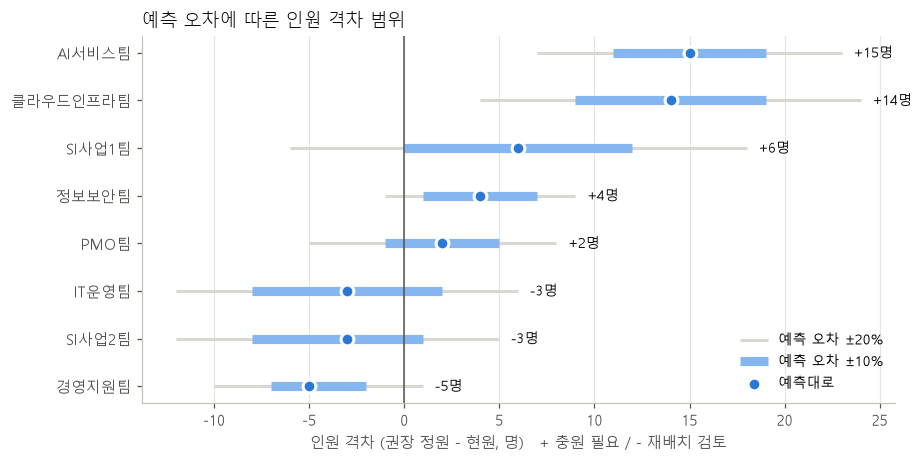

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.3))
order_b = table.sort_values("headcount_gap")["department_id"].tolist()
for y, d in enumerate(order_b):
    s = sens[sens["department_id"] == d].set_index("error")["headcount_gap"]
    ax.hlines(y, s[-0.2], s[0.2], color="#d8d7d1", lw=2, label="예측 오차 ±20%" if y == 0 else None)
    ax.hlines(y, s[-0.1], s[0.1], color="#86b6ef", lw=6, label="예측 오차 ±10%" if y == 0 else None)
    ax.scatter(s[0.0], y, s=70, color="#2a78d6", zorder=3, edgecolor="white", lw=2, label="예측대로" if y == 0 else None)
    ax.text(s[0.2] + 0.6, y, f"{s[0.0]:+d}명", va="center", fontsize=9, color=INK)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(len(order_b)), names[order_b])
ax.set_xlabel("인원 격차 (권장 정원 - 현원, 명)   + 충원 필요 / - 재배치 검토")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("예측 오차에 따른 인원 격차 범위", loc="left", color=INK)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(IMG / "b_sensitivity.png", bbox_inches="tight")

**해석 (Module B)**
- **AI서비스팀·클라우드인프라팀**: 실제 업무량이 예측보다 20% 적더라도 충원이 필요합니다 → 예측 오차에 흔들리지 않는 **확실한 충원 대상**.
- **정보보안팀**: 규모는 작지만 ±10% 안에서 항상 충원 방향(+1~+7명) → 충원 판단이 안정적.
- **경영지원팀**: ±10% 안에서 항상 인원 여유 → 재배치 검토 판단이 안정적.
- **SI사업1팀·SI사업2팀·IT운영팀·PMO팀**: ±10% 오차 안에서 판단 방향이 바뀝니다. 정원을 바로 조정하기보다 분기별 실적을 확인하며 결정하는 편이 맞습니다.
- 권장 정원은 12개월 **평균** 기준입니다. 분기말 피크(필요 FTE 피크월)는 평균보다 높으므로, 피크는 정원이 아닌 일시 지원·조직 간 협업으로 대응할지 별도 판단이 필요합니다.
- 다음 단계(Module C): 충원을 외부 채용만으로 할지, 저활용 조직 인력을 스킬 기준으로 재배치할 수 있는지 확인합니다.